# Proyecto 1 — Análisis exploratorio de datos del Titanic

**Módulo:** Fundamentos de Inteligencia Artificial · Maestría en Ciencia de Datos  
**Objetivo:** describir la calidad de datos y explorar asociaciones entre la supervivencia y características de los pasajeros.

**Preguntas de investigación:**
1. ¿Qué proporción de pasajeros sobrevivió?
2. ¿Cómo varía la supervivencia según el sexo y la clase?
3. ¿Qué patrones se observan en la edad y el precio del boleto?
4. ¿Cuáles son las limitaciones y los valores faltantes de esta base?

> Los análisis estadísticos describen **asociaciones**, no relaciones causales. Se utiliza el conjunto de datos proporcionado para el taller (891 registros).

## 1. Lectura de datos y estructura
El notebook busca `data/titanic.csv` desde la carpeta del proyecto o desde `notebooks/`, por lo que puede ejecutarse tanto en VS Code como desde la terminal.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, norm
from IPython.display import display

sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if not (ROOT / "data" / "titanic.csv").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "titanic.csv"
if not DATA.is_file():
    raise FileNotFoundError(f"No se encontro el dataset: {DATA}")
df = pd.read_csv(DATA)
assert df.shape == (891, 12), f"Dimensiones inesperadas: {df.shape}"
print(f"Registros: {len(df)} | Variables: {len(df.columns)}")
display(df.head())

Registros: 891 | Variables: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print("Tipos de datos:")
display(df.dtypes.rename("tipo").to_frame())
print("Resumen descriptivo:")
display(df.describe(include="all").T)

Tipos de datos:


,tipo
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


Resumen descriptivo:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


## 2. Calidad de los datos
En lugar de eliminar filas o imputar valores sin evidencia, cuantificamos primero los valores faltantes. `Age` tiene 177 ausencias; `Cabin`, 687; `Embarked`, 2. La variable `Survived` no tiene faltantes.

,faltantes,porcentaje
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


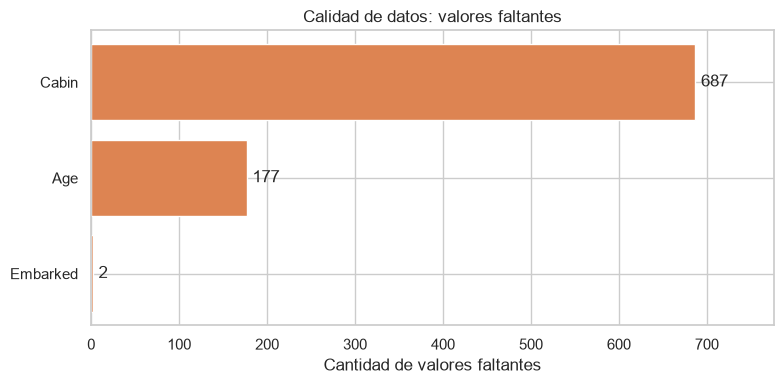

In [3]:
missing = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "porcentaje": (100 * df.isna().mean()).round(2)
}).sort_values("faltantes", ascending=False)
display(missing)
missing_nonzero = missing[missing["faltantes"] > 0].sort_values("faltantes")
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(missing_nonzero.index, missing_nonzero["faltantes"], color="#DD8452")
ax.bar_label(bars, padding=4)
ax.set_xlim(0, missing_nonzero["faltantes"].max() * 1.13)
ax.set_xlabel("Cantidad de valores faltantes")
ax.set_title("Calidad de datos: valores faltantes")
plt.tight_layout()
plt.show()

In [4]:
checks = pd.Series({
    "filas_duplicadas": int(df.duplicated().sum()),
    "PassengerId_duplicados": int(df["PassengerId"].duplicated().sum()),
    "edades_negativas": int((df["Age"] < 0).sum()),
    "tarifas_negativas": int((df["Fare"] < 0).sum()),
    "supervivencia_fuera_de_0_1": int((~df["Survived"].isin([0, 1])).sum()),
    "clase_fuera_de_1_2_3": int((~df["Pclass"].isin([1, 2, 3])).sum())
}, name="incidencias")
display(checks.to_frame())
assert (checks == 0).all(), "Existe alguna incidencia que debe investigarse"

,incidencias
filas_duplicadas,0
PassengerId_duplicados,0
edades_negativas,0
tarifas_negativas,0
supervivencia_fuera_de_0_1,0
clase_fuera_de_1_2_3,0


## 3. Supervivencia general
`Survived = 1` indica que el pasajero sobrevivió y `Survived = 0` que no. Las tasas se obtienen dividiendo el número de supervivientes por el total de pasajeros del grupo correspondiente.

Supervivientes: 342 de 891 (38.38%)


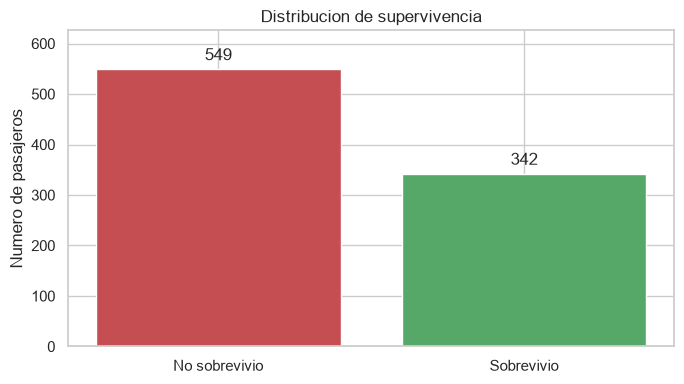

In [5]:
counts = df["Survived"].value_counts().reindex([0, 1], fill_value=0)
rate = 100 * df["Survived"].mean()
print(f"Supervivientes: {counts[1]} de {len(df)} ({rate:.2f}%)")
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["No sobrevivio", "Sobrevivio"], counts.values, color=["#C44E52", "#55A868"])
ax.bar_label(bars, padding=4)
ax.set_ylim(0, counts.max() * 1.14)
ax.set_ylabel("Numero de pasajeros")
ax.set_title("Distribucion de supervivencia")
plt.tight_layout()
plt.show()

## 4. Comparaciones por sexo y clase
La media de una variable binaria como `Survived` equivale a la proporción de supervivientes. Se reportan los denominadores de cada grupo para evitar interpretar tasas sin contexto.

In [6]:
for col in ["Sex", "Pclass"]:
    summary = df.groupby(col)["Survived"].agg(
        pasajeros="count", supervivientes="sum", proporcion="mean"
    )
    summary["tasa_pct"] = (100 * summary.pop("proporcion")).round(2)
    print(f"Supervivencia por {col}:")
    display(summary)

Supervivencia por Sex:


,pasajeros,supervivientes,tasa_pct
Sex,,,
female,314,233,74.20
male,577,109,18.89


Supervivencia por Pclass:


,pasajeros,supervivientes,tasa_pct
Pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


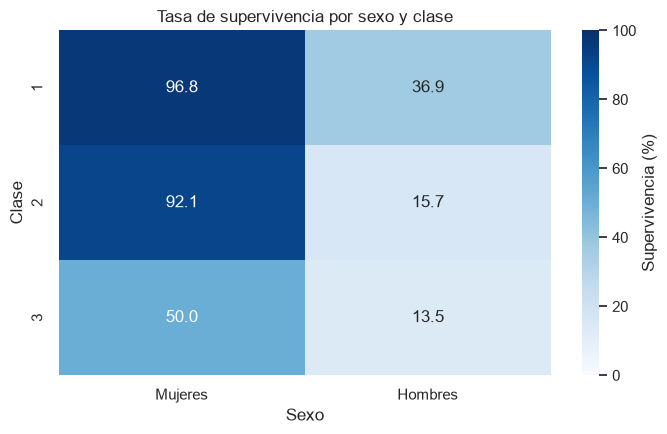

In [7]:
pivot = 100 * df.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean")
pivot = pivot.reindex(index=[1, 2, 3], columns=["female", "male"])
pivot.columns = ["Mujeres", "Hombres"]
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(pivot, annot=True, fmt=".1f", vmin=0, vmax=100, cmap="Blues",
            cbar_kws={"label": "Supervivencia (%)"}, ax=ax)
ax.set_xlabel("Sexo")
ax.set_ylabel("Clase")
ax.set_title("Tasa de supervivencia por sexo y clase")
plt.tight_layout()
plt.show()

## 5. Edad y tarifa
Los histogramas normalizados por grupo permiten comparar **formas de distribución**, no tasas de supervivencia condicionadas a cada edad. La edad es desconocida para 177 personas, por lo que estas distribuciones solamente reflejan casos con edad registrada. Los valores extremos de `Fare` se investigan, no se eliminan automáticamente.

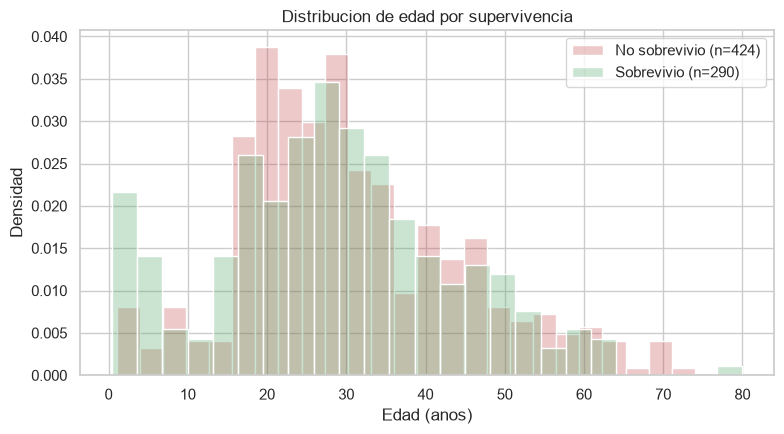

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for survived, label, color in [(0, "No sobrevivio", "#C44E52"), (1, "Sobrevivio", "#55A868")]:
    subset = df.loc[df["Survived"] == survived, "Age"].dropna()
    sns.histplot(subset, bins=25, stat="density", alpha=0.3,
                 label=f"{label} (n={len(subset)})", color=color, ax=ax)
ax.set_title("Distribucion de edad por supervivencia")
ax.set_xlabel("Edad (anos)")
ax.set_ylabel("Densidad")
ax.legend()
plt.tight_layout()
plt.show()

Fare: Q1=7.91, Q3=31.00, IQR=23.09
Umbral superior de Tukey: 65.63; valores superiores: 116


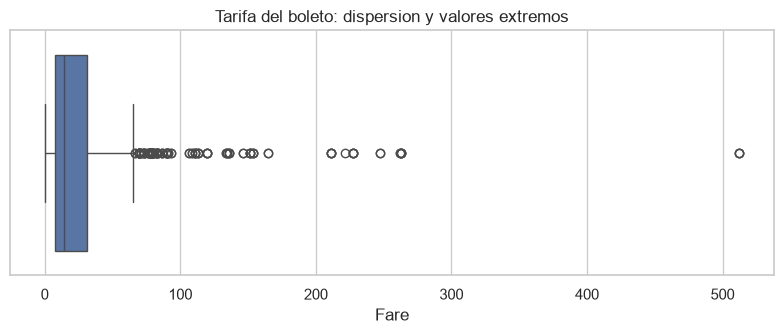

In [9]:
q1, q3 = df["Fare"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
outlier_count = int((df["Fare"] > upper).sum())
print(f"Fare: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")
print(f"Umbral superior de Tukey: {upper:.2f}; valores superiores: {outlier_count}")
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(x=df["Fare"], color="#4C72B0", ax=ax)
ax.set_title("Tarifa del boleto: dispersion y valores extremos")
ax.set_xlabel("Fare")
plt.tight_layout()
plt.show()

## 6. Extensión: inferencia estadística
Se utiliza la prueba $\chi^2$ de independencia, sin corrección de continuidad, y V de Cramér para describir la fuerza de asociación. También se presentan intervalos de Wilson del 95 % para cada proporción. **Precaución:** los valores p suponen independencia de observaciones, un supuesto discutible entre familiares y pasajeros que compartían boleto; además, el conjunto no es necesariamente una muestra aleatoria representativa.

In [10]:
resultados = []
for variable in ["Sex", "Pclass"]:
    contingency = pd.crosstab(df[variable], df["Survived"])
    chi2, p_value, gl, expected = chi2_contingency(contingency, correction=False)
    n = contingency.to_numpy().sum()
    cramer_v = np.sqrt(chi2 / (n * min(contingency.shape[0]-1, contingency.shape[1]-1)))
    resultados.append({"variable": variable, "chi2": chi2, "gl": gl,
                       "valor_p": p_value, "V_de_Cramer": cramer_v,
                       "min_esperado": expected.min()})
display(pd.DataFrame(resultados))

,variable,chi2,gl,valor_p,V_de_Cramer,min_esperado
0,Sex,263.050574,1,3.711748e-59,0.543351,120.525253
1,Pclass,102.888989,2,4.549252e-23,0.339817,70.626263


In [11]:
z = norm.ppf(0.975)
def wilson(successes, total):
    p = successes / total
    denominator = 1 + z*z/total
    center = (p + z*z/(2*total)) / denominator
    half = (z / denominator) * np.sqrt(p*(1-p)/total + z*z/(4*total*total))
    return center-half, center+half

rows = []
for cls in [1, 2, 3]:
    for sex in ["female", "male"]:
        group = df.loc[(df["Pclass"] == cls) & (df["Sex"] == sex), "Survived"]
        lower, upper = wilson(group.sum(), len(group))
        rows.append({"clase": cls, "sexo": sex, "n": len(group),
                     "tasa_pct": 100*group.mean(),
                     "IC95_inf_pct": 100*lower, "IC95_sup_pct": 100*upper})
intervals = pd.DataFrame(rows)
display(intervals.round(2))

,clase,sexo,n,tasa_pct,IC95_inf_pct,IC95_sup_pct
0,1,female,94,96.81,91.03,98.91
1,1,male,122,36.89,28.85,45.73
2,2,female,76,92.11,83.83,96.33
3,2,male,108,15.74,10.07,23.77
4,3,female,144,50.00,41.94,58.06
5,3,male,347,13.54,10.34,17.55


## 7. Conclusiones y limitaciones

1. En los **891 registros**, **342 personas sobrevivieron** (38,38 %).
2. La tasa de supervivencia fue de **74,20 % en mujeres** y **18,89 % en hombres**: una diferencia de **55,31 puntos porcentuales**.
3. Las tasas de supervivencia por clase fueron **62,96 % (primera)**, **47,28 % (segunda)** y **24,24 % (tercera)**. La desagregación conjunta confirma que sexo y clase se relacionan con la supervivencia, sin probar causalidad.
4. Las variables **Cabin (77,10 %)** y **Age (19,87 %)** tienen valores faltantes sustanciales. Por tanto, los resultados basados en ellas pueden estar sesgados.
5. Las pruebas de asociación y los intervalos de confianza se añaden como extensión a un EDA básico. Sus resultados deben interpretarse con los supuestos y límites del dataset.

**Decisiones metodológicas:** se conserva el CSV original sin alteraciones; no se imputan edades ni se eliminan valores extremos sin una justificación adicional. Este notebook se enfoca en exploración, no en predicción, para respetar la actividad calificable.